# Machine Learning and Deep Learning for Forecasting
### DSO 522 · Applied Time Series Forecasting · Hands-on notebook

**Business problem.** A utility must schedule power plants one day ahead. Every afternoon it forecasts the load (electricity demand, in megawatts) for each of the 24 hours of tomorrow. Too low a forecast means buying expensive power at the last minute; too high means paying for generation nobody uses.

**What you will do**
1. Turn a time series into a table a machine learning model can learn from (feature engineering).
2. Train gradient boosting (LightGBM) and a random forest on those features.
3. Use the production-style Nixtla libraries: `statsforecast`, `mlforecast`, `neuralforecast`.
4. Train a deep learning model (N-HiTS) and run a pretrained foundation model (Chronos).
5. Compare every model on the same 14 days and translate the accuracy gap into money.

**Learning outcomes.** By the end you can build leakage-free lag, rolling, calendar and weather features; train and evaluate tree, deep learning and foundation models; and defend which model you would deploy.

*AI coding assistants (Gemini, ChatGPT) are welcome for syntax. The interpretation of results is yours.*

## 1. Setup

In [ ]:
# Run once in Colab (Runtime > Change runtime type > T4 GPU is only needed for Chronos and speeds up N-HiTS)
%pip install -q statsforecast mlforecast neuralforecast utilsforecast lightgbm chronos-forecasting

In [2]:
import time
import warnings
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from pandas.tseries.holiday import USFederalHolidayCalendar

plt.rcParams['figure.figsize'] = (12, 4)
warnings.filterwarnings("ignore")
for name in ["pytorch_lightning", "lightning.pytorch", "lightning_fabric", "ray"]:
    logging.getLogger(name).setLevel(logging.ERROR)

In [3]:
# Option A: upload energy.csv from your computer (Colab only)
# from google.colab import files
# uploaded = files.upload()

In [4]:
df = pd.read_csv("https://raw.githubusercontent.com/robertasgabrys/ForecastingData/main/energy.csv",
                 parse_dates=["timestamp"])
df = df.rename(columns={"timestamp": "ds", "load": "y"})
df.head()

,ds,y,temp
0,2012-01-01 00:00:00,2698.0,32.000000
1,2012-01-01 01:00:00,2558.0,32.666667
2,2012-01-01 02:00:00,2444.0,30.000000
3,2012-01-01 03:00:00,2402.0,31.000000
4,2012-01-01 04:00:00,2403.0,32.000000


The data: hourly load (MW) and temperature (°F) from January 2012 to December 2014. That is 26,304 hours with no gaps. We will forecast the last 14 days (December 18–31, 2014) one day at a time, the way a utility does.

In [5]:
print(df.shape)
print(df["ds"].min(), "to", df["ds"].max())
df.describe()

(26304, 3)
2012-01-01 00:00:00 to 2014-12-31 23:00:00


,ds,y,temp
count,26304,26304.000000,26304.000000
mean,2013-07-01 23:30:00,3303.769199,47.765638
min,2012-01-01 00:00:00,1979.000000,-13.666667
25%,2012-09-30 23:45:00,2867.000000,32.666667
50%,2013-07-01 23:30:00,3364.000000,48.333333
75%,2014-04-01 23:15:00,3690.000000,63.666667
max,2014-12-31 23:00:00,5224.000000,95.000000
std,NaN,564.579253,19.338142


## 2. Look at the data before modeling

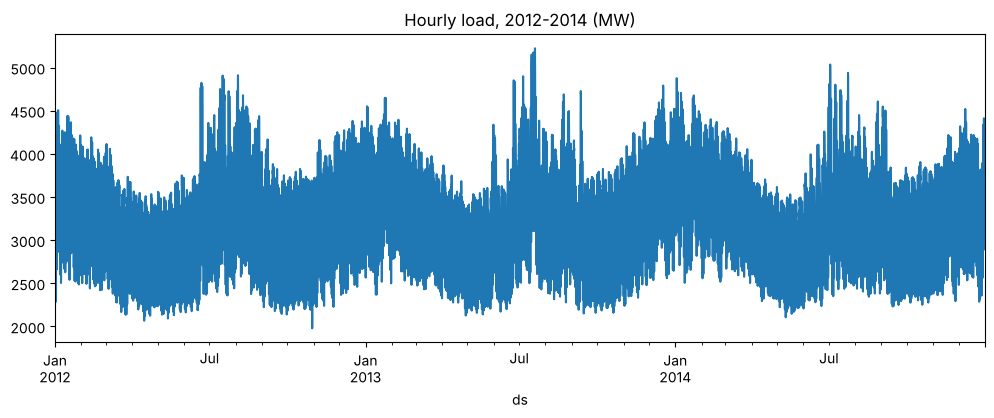

In [6]:
df.plot(x="ds", y="y", legend=False, title="Hourly load, 2012-2014 (MW)")
plt.show()

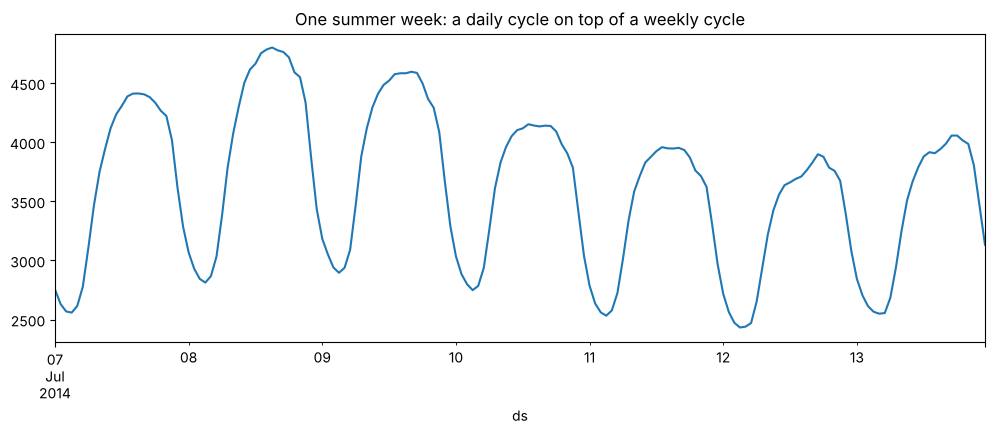

In [7]:
one_week = df[(df["ds"] >= "2014-07-07") & (df["ds"] < "2014-07-14")]
one_week.plot(x="ds", y="y", legend=False, title="One summer week: a daily cycle on top of a weekly cycle")
plt.show()

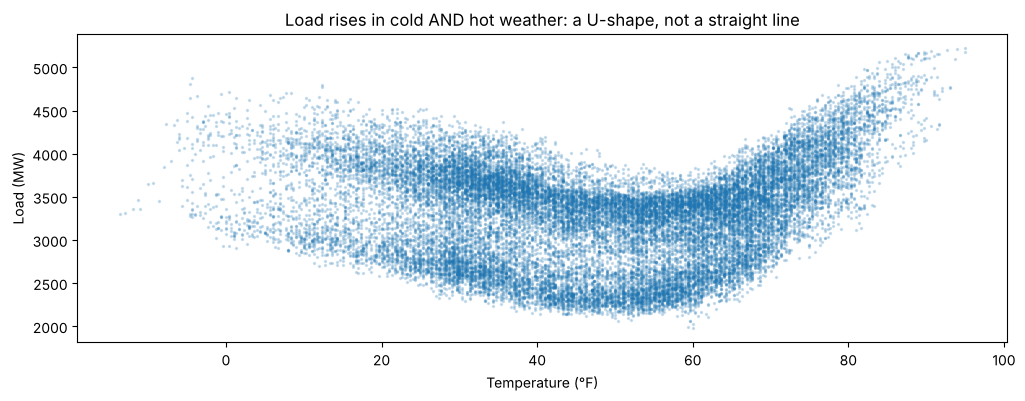

Correlation between load and temperature: 0.073


In [8]:
plt.scatter(df["temp"], df["y"], s=2, alpha=0.2)
plt.xlabel("Temperature (°F)")
plt.ylabel("Load (MW)")
plt.title("Load rises in cold AND hot weather: a U-shape, not a straight line")
plt.show()
print("Correlation between load and temperature:", round(df["y"].corr(df["temp"]), 3))

**Question 1.** The correlation between load and temperature is close to zero. Does that mean temperature is useless for forecasting? Use the scatter plot to explain.

*Answer:* No. The relationship is strong but U-shaped: load is high in cold weather (heating) and in hot weather (air conditioning). Correlation only measures straight-line relationships, so it misses this. We will capture the U-shape with features (heating and cooling degrees), and tree models can learn it on their own.

## 3. Feature engineering: turn the series into a table

A machine learning model does not know about time. It learns from a table where **each row is one hour** and **each column is something we knew before that hour**. Building those columns is called feature engineering, and it usually matters more than the choice of model.

**The availability rule.** We forecast tomorrow's 24 hours at midnight. So for any hour we may only use load values from **24 or more hours earlier**. Temperature is treated as known, because utilities buy a day-ahead weather forecast (here we use actual temperatures, which makes our results slightly optimistic).

### 3.1 Calendar features

In [9]:
X = df.copy()
X["hour"] = X["ds"].dt.hour
X["dayofweek"] = X["ds"].dt.dayofweek          # Monday = 0
X["month"] = X["ds"].dt.month
X["dayofyear"] = X["ds"].dt.dayofyear
X["weekend"] = (X["dayofweek"] >= 5).astype(int)

holidays = USFederalHolidayCalendar().holidays(start=X["ds"].min(), end=X["ds"].max())
X["holiday"] = X["ds"].dt.normalize().isin(holidays).astype(int)

# Cyclical encoding: hour 23 and hour 0 are neighbors (helps linear models and neural nets, not trees)
X["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
X["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)
X[["ds", "hour", "dayofweek", "weekend", "holiday", "hour_sin", "hour_cos"]].head(3)

,ds,hour,dayofweek,weekend,holiday,hour_sin,hour_cos
0,2012-01-01 00:00:00,0,6,1,0,0.000000,1.000000
1,2012-01-01 01:00:00,1,6,1,0,0.258819,0.965926
2,2012-01-01 02:00:00,2,6,1,0,0.500000,0.866025


### 3.2 Lag features: what happened at the same hour yesterday and last week

In [10]:
X["lag24"] = X["y"].shift(24)     # same hour yesterday
X["lag48"] = X["y"].shift(48)     # same hour two days ago
X["lag168"] = X["y"].shift(168)   # same hour last week
X[["ds", "y", "lag24", "lag168"]].iloc[166:170]

,ds,y,lag24,lag168
166,2012-01-07 22:00:00,3062.0,3244.0,NaN
167,2012-01-07 23:00:00,2850.0,2981.0,NaN
168,2012-01-08 00:00:00,2654.0,2790.0,2698.0
169,2012-01-08 01:00:00,2567.0,2685.0,2558.0


### 3.3 Rolling-window features: recent level and volatility

In [11]:
# Always shift FIRST, then roll: the window must end 24 hours before the hour we forecast
X["roll_mean_24"] = X["y"].shift(24).rolling(24).mean()     # average load over the last known day
X["roll_std_24"] = X["y"].shift(24).rolling(24).std()       # how volatile that day was
X["roll_mean_168"] = X["y"].shift(24).rolling(168).mean()   # average over the last known week

### 3.4 Weather features

In [12]:
X["HDD"] = (65 - X["temp"]).clip(lower=0)      # heating degrees: how far below 65°F
X["CDD"] = (X["temp"] - 65).clip(lower=0)      # cooling degrees: how far above 65°F
X["temp_lag1"] = X["temp"].shift(1)            # buildings react with a delay (thermal inertia)
X["temp_lag3"] = X["temp"].shift(3)
X["temp_mean_24"] = X["temp"].rolling(24).mean()   # a hot DAY drives load more than a hot hour

In [13]:
X = X.dropna()          # the first week has no lag168 value
features = [c for c in X.columns if c not in ["ds", "y"]]
print(len(features), "features:", features)

20 features: ['temp', 'hour', 'dayofweek', 'month', 'dayofyear', 'weekend', 'holiday', 'hour_sin', 'hour_cos', 'lag24', 'lag48', 'lag168', 'roll_mean_24', 'roll_std_24', 'roll_mean_168', 'HDD', 'CDD', 'temp_lag1', 'temp_lag3', 'temp_mean_24']


### 3.5 Time-based train/test split

Never shuffle time series. Train on everything before December 18, 2014; test on the 14 days after.

In [14]:
cutoff = pd.Timestamp("2014-12-18")
train = X[X["ds"] < cutoff]
test = X[X["ds"] >= cutoff]
print("train:", train.shape, " test:", test.shape)

def score(name, actual, forecast, seconds=None):
    err = actual - forecast
    return {"model": name,
            "MAE (MW)": np.mean(np.abs(err)),
            "RMSE (MW)": np.sqrt(np.mean(err ** 2)),
            "MAPE (%)": 100 * np.mean(np.abs(err) / actual),
            "seconds": seconds}

results = []

train: (25777, 22)  test: (336, 22)


## 4. Baselines every model must beat

In [15]:
results.append(score("Seasonal naive (same hour yesterday)", test["y"], test["lag24"]))
results.append(score("Seasonal naive (same hour last week)", test["y"], test["lag168"]))
pd.DataFrame(results).round(2)

,model,MAE (MW),RMSE (MW),MAPE (%),seconds
0,Seasonal naive (same hour yesterday),157.35,212.65,4.76,None
1,Seasonal naive (same hour last week),249.86,322.19,7.82,None


## 5. Gradient boosting with LightGBM

**Intuition.** LightGBM builds hundreds of small decision trees, one after another. Each new tree focuses on the errors the previous trees still make. Think of a relay team where each runner makes up for the last runner's mistakes.

In [16]:
start = time.time()
lgbm = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, verbosity=-1)
lgbm.fit(train[features], train["y"])
lgbm_pred = lgbm.predict(test[features])
results.append(score("LightGBM (all features)", test["y"], lgbm_pred, time.time() - start))
pd.DataFrame(results).round(2)

,model,MAE (MW),RMSE (MW),MAPE (%),seconds
0,Seasonal naive (same hour yesterday),157.35,212.65,4.76,NaN
1,Seasonal naive (same hour last week),249.86,322.19,7.82,NaN
2,LightGBM (all features),66.34,91.46,2.00,0.83


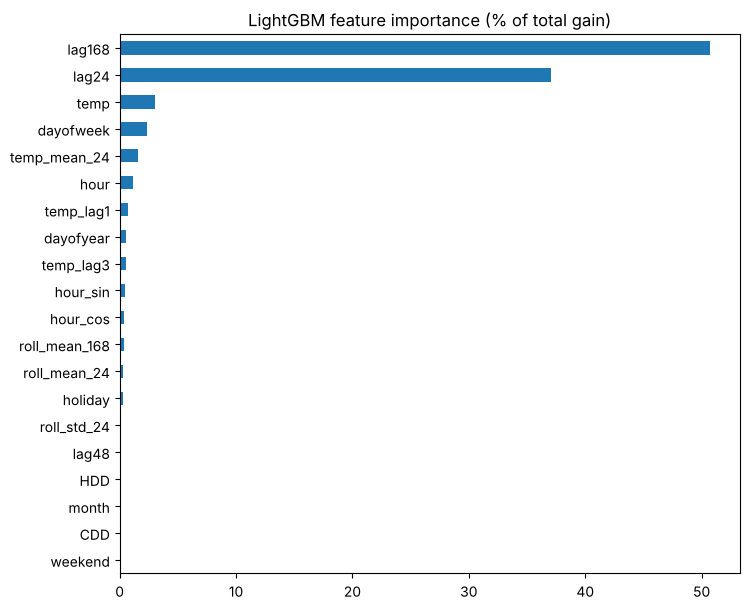

In [17]:
importance = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"), index=features)
importance = 100 * importance / importance.sum()
importance.sort_values().plot(kind="barh", figsize=(8, 7), title="LightGBM feature importance (% of total gain)")
plt.show()

**Question 2.** Which two features dominate, and why does that make sense for electricity load?

*Answer:* `lag168` and `lag24`, the same hour last week and yesterday. Load repeats daily and weekly, so recent same-hour values are the best single guide. Temperature features come next: they tell the model how tomorrow differs from yesterday.

### 5.1 What does each feature group add? (ablation)

In [18]:
weather = ["temp", "HDD", "CDD", "temp_lag1", "temp_lag3", "temp_mean_24"]
lags = ["lag24", "lag48", "lag168", "roll_mean_24", "roll_std_24", "roll_mean_168"]

for name, cols in [("LightGBM without weather", [f for f in features if f not in weather]),
                   ("LightGBM without lags", [f for f in features if f not in lags])]:
    m = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, verbosity=-1).fit(train[cols], train["y"])
    results.append(score(name, test["y"], m.predict(test[cols])))
pd.DataFrame(results).round(2)

,model,MAE (MW),RMSE (MW),MAPE (%),seconds
0,Seasonal naive (same hour yesterday),157.35,212.65,4.76,NaN
1,Seasonal naive (same hour last week),249.86,322.19,7.82,NaN
2,LightGBM (all features),66.34,91.46,2.00,0.83
3,LightGBM without weather,131.51,164.94,4.13,NaN
4,LightGBM without lags,85.39,116.98,2.65,NaN


**Question 3.** Removing the weather features roughly doubles the error. Removing the lags hurts much less. What does this tell you about where the forecasting skill comes from in this problem?

*Answer:* Lags tell the model the usual shape of a day; weather tells it how tomorrow will be different. For a weather-driven series, knowing tomorrow's temperature is worth more than knowing last week's load in detail.

### 5.2 A warning: feature leakage looks like genius

In [19]:
leaky = train.copy()
leaky_test = test.copy()
for d in (leaky, leaky_test):
    d["roll_mean_LEAK"] = d["y"].rolling(3, min_periods=1).mean()   # includes the current hour: forbidden!
m = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, verbosity=-1)
m.fit(leaky[features + ["roll_mean_LEAK"]], leaky["y"])
leak_pred = m.predict(leaky_test[features + ["roll_mean_LEAK"]])
print("MAPE with a leaked feature:", round(100 * np.mean(np.abs(test["y"] - leak_pred) / test["y"]), 2), "%")

MAPE with a leaked feature: 0.67 %


A near-perfect score is a red flag, not a success: this model secretly uses the value it is supposed to predict, and it would be useless in production.

## 6. Random forest

**Intuition.** Hundreds of deep trees, each trained on a random sample of rows and features, then averaged. Ask 500 analysts and average their answers.

In [20]:
start = time.time()
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=1)
rf.fit(train[features], train["y"])
rf_pred = rf.predict(test[features])
results.append(score("Random forest", test["y"], rf_pred, time.time() - start))
pd.DataFrame(results).round(2)

,model,MAE (MW),RMSE (MW),MAPE (%),seconds
0,Seasonal naive (same hour yesterday),157.35,212.65,4.76,NaN
1,Seasonal naive (same hour last week),249.86,322.19,7.82,NaN
2,LightGBM (all features),66.34,91.46,2.00,0.83
3,LightGBM without weather,131.51,164.94,4.13,NaN
4,LightGBM without lags,85.39,116.98,2.65,NaN
5,Random forest,102.35,138.99,3.12,26.02


## 7. The production way: Nixtla libraries

The Nixtla libraries automate what we did by hand. They all expect the same long format: `unique_id` (the series name), `ds` (time stamp), `y` (target), plus any extra input columns. Their `cross_validation()` method repeats the day-ahead forecast for each of the 14 test days, retraining as it goes.

In [21]:
nixtla_df = X[["ds", "y", "temp", "HDD", "CDD", "temp_lag1", "temp_mean_24", "holiday"]].copy()
nixtla_df.insert(0, "unique_id", "load")
nixtla_df.head(3)

,unique_id,ds,y,temp,HDD,CDD,temp_lag1,temp_mean_24,holiday
191,load,2012-01-08 23:00:00,2955.0,21.333333,43.666667,0.0,22.666667,30.000000,0
192,load,2012-01-09 00:00:00,2820.0,20.666667,44.333333,0.0,21.333333,29.513889,0
193,load,2012-01-09 01:00:00,2759.0,19.333333,45.666667,0.0,20.666667,29.041667,0


### 7.1 statsforecast: statistical baselines, including MSTL

In [22]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, MSTL, AutoETS

sf = StatsForecast(
    models=[SeasonalNaive(season_length=24, alias="Naive24"),
            MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN"), alias="MSTL")],
    freq="h")

start = time.time()
cv_stats = sf.cross_validation(df=nixtla_df[["unique_id", "ds", "y"]].tail(24 * 120), h=24, n_windows=14, step_size=24)
mstl_seconds = time.time() - start
cv_stats.head()

,unique_id,ds,cutoff,y,Naive24,MSTL
0,load,2014-12-18 00:00:00,2014-12-17 23:00:00,2703.0,2727.0,2733.706122
1,load,2014-12-18 01:00:00,2014-12-17 23:00:00,2608.0,2624.0,2632.373642
2,load,2014-12-18 02:00:00,2014-12-17 23:00:00,2566.0,2573.0,2596.509506
3,load,2014-12-18 03:00:00,2014-12-17 23:00:00,2568.0,2575.0,2603.457409
4,load,2014-12-18 04:00:00,2014-12-17 23:00:00,2683.0,2678.0,2701.568527


In [23]:
results.append(score("MSTL (statsforecast)", cv_stats["y"], cv_stats["MSTL"], mstl_seconds))

### 7.2 mlforecast: LightGBM with automatic lags, rolling windows and calendar features

In [24]:
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean, RollingStd

mlf = MLForecast(
    models={"LightGBM": lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, verbosity=-1)},
    freq="h",
    lags=[24, 48, 168],
    lag_transforms={24: [RollingMean(window_size=24), RollingStd(window_size=24)],
                    168: [RollingMean(window_size=168)]},
    date_features=["hour", "dayofweek", "month", "dayofyear"],
)

start = time.time()
cv_ml = mlf.cross_validation(df=nixtla_df, h=24, n_windows=14, step_size=24, static_features=[])
results.append(score("LightGBM (mlforecast, retrained daily)", cv_ml["y"], cv_ml["LightGBM"], time.time() - start))
cv_ml.head()

,unique_id,ds,cutoff,y,LightGBM
0,load,2014-12-18 00:00:00,2014-12-17 23:00:00,2703.0,2637.414499
1,load,2014-12-18 01:00:00,2014-12-17 23:00:00,2608.0,2559.504614
2,load,2014-12-18 02:00:00,2014-12-17 23:00:00,2566.0,2495.676077
3,load,2014-12-18 03:00:00,2014-12-17 23:00:00,2568.0,2518.991396
4,load,2014-12-18 04:00:00,2014-12-17 23:00:00,2683.0,2614.773946


`static_features=[]` tells mlforecast that every extra column (temperature, HDD, CDD, holiday) changes over time, so it is used as a known future input. For a real forecast you call `mlf.fit(nixtla_df, static_features=[])` and then `mlf.predict(h=24, X_df=tomorrow)`, where `tomorrow` holds the 24 hours of forecast temperature.

## 8. Deep learning with N-HiTS (neuralforecast)

**Intuition.** N-HiTS is a neural network made of stacked blocks. One block captures the slow movement, the next the daily cycle, the next the fine detail; each passes what it could not explain to the next. It is a decomposition the network learns by itself. It reads the last week (168 hours) and outputs the next 24 hours at once.

In [25]:
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS

nhits = NHITS(h=24, input_size=168, max_steps=300, scaler_type="robust",
              futr_exog_list=["temp"], random_seed=1,
              enable_progress_bar=False, enable_model_summary=False, logger=False)
nf = NeuralForecast(models=[nhits], freq="h")

start = time.time()
cv_nn = nf.cross_validation(df=nixtla_df[["unique_id", "ds", "y", "temp"]], n_windows=14, step_size=24)
results.append(score("N-HiTS with temperature (neuralforecast)", cv_nn["y"], cv_nn["NHITS"], time.time() - start))
cv_nn.head()

2026-11-03 21:50:19,447	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-03 21:50:19,648	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Seed set to 1


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


`Trainer.fit` stopped: `max_steps=300` reached.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


,unique_id,ds,cutoff,NHITS,y
0,load,2014-12-18 00:00:00,2014-12-17 23:00:00,2718.978760,2703.0
1,load,2014-12-18 01:00:00,2014-12-17 23:00:00,2623.826660,2608.0
2,load,2014-12-18 02:00:00,2014-12-17 23:00:00,2593.215576,2566.0
3,load,2014-12-18 03:00:00,2014-12-17 23:00:00,2579.471436,2568.0
4,load,2014-12-18 04:00:00,2014-12-17 23:00:00,2638.792969,2683.0


Practical notes: `scaler_type="robust"` rescales each window so the network trains stably; `max_steps` is the training budget (more steps on a GPU usually helps); always fix `random_seed` so results are reproducible.

## 9. A foundation model: Chronos (zero-shot)

**Intuition.** Chronos was pretrained by Amazon on a huge collection of time series. Like ChatGPT for numbers, it forecasts a new series without any training on it. This version uses only the load history, not temperature.

*Run this cell in Colab: it downloads the model from Hugging Face the first time (a GPU makes it faster, but CPU works).*

In [ ]:
import torch
from chronos import BaseChronosPipeline

pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu")

chronos_preds = []
start = time.time()
for day in pd.date_range("2014-12-18", periods=14, freq="D"):
    history = df[df["ds"] < day]["y"].tail(2048)          # the context: recent history only
    quantiles, mean = pipe.predict_quantiles(context=torch.tensor(history.values, dtype=torch.float32),
                                             prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])
    chronos_preds.append(quantiles[0, :, 1].numpy())     # the median forecast
chronos_pred = np.concatenate(chronos_preds)
results.append(score("Chronos-Bolt small (zero-shot)", test["y"].values, chronos_pred, time.time() - start))

## 10. The bake-off

In [27]:
board = pd.DataFrame(results).sort_values("MAE (MW)").round(2)
board

,model,MAE (MW),RMSE (MW),MAPE (%),seconds
2,LightGBM (all features),66.34,91.46,2.00,0.83
7,"LightGBM (mlforecast, retrained daily)",79.35,103.06,2.38,14.02
4,LightGBM without lags,85.39,116.98,2.65,NaN
8,N-HiTS with temperature (neuralforecast),94.30,148.24,2.83,38.27
5,Random forest,102.35,138.99,3.12,26.02
6,MSTL (statsforecast),125.95,187.22,3.85,10.67
3,LightGBM without weather,131.51,164.94,4.13,NaN
0,Seasonal naive (same hour yesterday),157.35,212.65,4.76,NaN
1,Seasonal naive (same hour last week),249.86,322.19,7.82,NaN


**Question 4.** Rank the models. Which beats the seasonal naive baseline by the most? Is the winner worth its extra complexity?

**Question 5.** The two LightGBM rows differ. The hand-built one uses more weather features and was trained once; the mlforecast one has fewer weather features and is retrained every day. Which difference matters more? (Hint: compare with the "without weather" ablation.)

2014-12-29: daily mean temperature changed by -12.8 °F from the day before


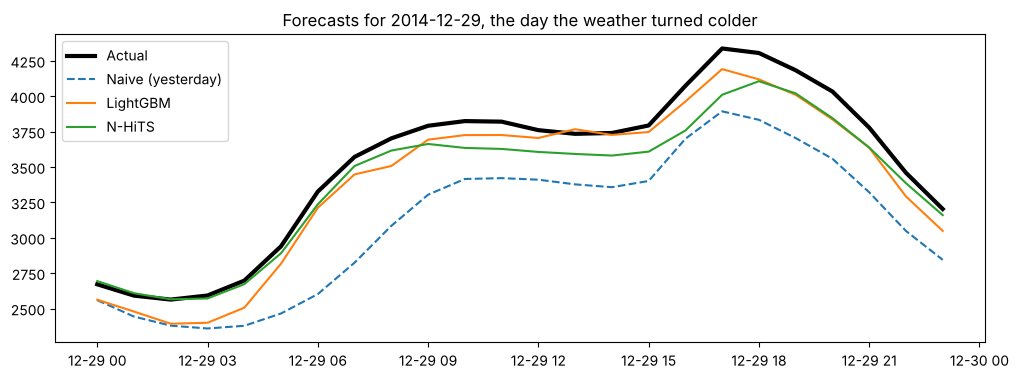

In [28]:
# Plot the test day when the temperature changed most from the day before: who reacts?
daily_temp = X.set_index("ds")["temp"].resample("D").mean()
swing = (daily_temp - daily_temp.shift(1)).loc["2014-12-18":]
day = swing.abs().idxmax()
print(f"{day.date()}: daily mean temperature changed by {swing[day]:.1f} °F from the day before")
next_day = day + pd.Timedelta(days=1)
mask = (test["ds"] >= day) & (test["ds"] < next_day)
plt.plot(test.loc[mask, "ds"], test.loc[mask, "y"], "k-", lw=3, label="Actual")
plt.plot(test.loc[mask, "ds"], test.loc[mask, "lag24"], "--", label="Naive (yesterday)")
plt.plot(test.loc[mask, "ds"], lgbm_pred[mask.values], label="LightGBM")
nn_day = cv_nn[(cv_nn["ds"] >= day) & (cv_nn["ds"] < next_day)]
plt.plot(nn_day["ds"], nn_day["NHITS"], label="N-HiTS")
plt.title(f"Forecasts for {day.date()}, the day the weather turned colder")
plt.legend()
plt.show()

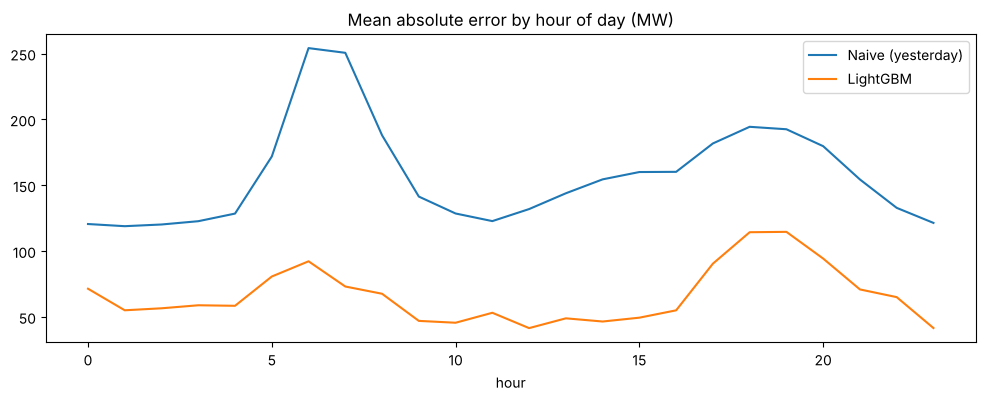

In [29]:
# Where in the day are the errors? Mean absolute error by hour of day
err = pd.DataFrame({"hour": test["hour"].values,
                    "Naive (yesterday)": np.abs(test["y"] - test["lag24"]).values,
                    "LightGBM": np.abs(test["y"].values - lgbm_pred)})
err.groupby("hour").mean().plot(title="Mean absolute error by hour of day (MW)")
plt.show()

### 10.1 Translate accuracy into money

In [30]:
cost_per_mwh_of_error = 20      # assumption: balancing cost of each MWh forecast wrong ($)
naive_mae = board.loc[board["model"] == "Seasonal naive (same hour yesterday)", "MAE (MW)"].iloc[0]
best = board.iloc[0]
saving = (naive_mae - best["MAE (MW)"]) * 24 * 365 * cost_per_mwh_of_error
print(f"Best model: {best['model']}")
print(f"Error reduction vs naive: {naive_mae - best['MAE (MW)']:.0f} MW per hour")
print(f"Illustrative yearly saving at ${cost_per_mwh_of_error}/MWh: ${saving:,.0f}")

Best model: LightGBM (all features)
Error reduction vs naive: 91 MW per hour
Illustrative yearly saving at $20/MWh: $15,944,952


**Question 6.** Change `cost_per_mwh_of_error` to a value you think is realistic and recompute. At what cost per MWh does a data science team of two people (about $400,000 a year) pay for itself?

**Question 7.** Name two reasons the accuracy you see here would be worse in real operations. (Hints: where did the temperature come from? What happens on holidays the model rarely saw?)

## 11. Takeaways for practice

- Start with a seasonal naive baseline and keep it in every comparison.
- Feature engineering (lags, rolling windows, calendar, weather) drives most of the accuracy of tree models.
- LightGBM is the default workhorse when you have useful outside drivers such as temperature.
- Deep learning shines with many related series and long histories; on one series it is often matched by a well-engineered LightGBM.
- Foundation models give a strong baseline in minutes with no training, but most versions cannot use known future drivers like the temperature forecast.
- Always evaluate with time-based cross-validation and check for leakage: results that look too good usually are.